<a href="https://colab.research.google.com/github/oojobe/FB-/blob/main/Grp_4_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Step 1: Import Libraries

Before building the dashboard, we import every library the project needs. Each one has a specific job:

| Import | What it is | Why we use it in this dashboard |
|---|---|---|
| `threading` | Python's built-in module for working with threads | Dash runs several chart callbacks **at the same time** in separate threads. We use `threading.local()` to give each thread its own private copy of the current theme (light/dark), so charts drawn in parallel never pick up each other's colours. |
| `from urllib.parse import quote` | A built-in function that makes text safe to use inside a URL | The sun and moon icons on the light/dark toggle are SVG images embedded directly in the CSS. `quote()` encodes the SVG code (spaces, `<`, `>`, `#` and so on) so the browser can read it as an image. |
| `numpy as np` | The standard library for fast numerical calculations | Used to create new columns with conditions, e.g. `np.where()` to calculate the **Response Gap** only for rows where an accident happened, and to label vehicles as **"Over limit"** or **"Within limit"**. |
| `pandas as pd` | The main library for working with tables (DataFrames) | Loads the cleaned CSV, converts dates, creates bands (congestion, age, experience) with `pd.cut()`, filters data, and calculates accident rates with `groupby()`. |
| `plotly.express as px` | Plotly's high-level charting library, which builds a chart in one line | Creates almost every chart in the dashboard: bar, line, box, pie, heatmap (`px.imshow`), sunburst and treemap. |
| `plotly.graph_objects as go` | Plotly's low-level charting library, with full control over every element | Used to build an **empty placeholder chart** with a "No data for this selection" message when the filters return no rows. |
| `Dash` | The main class that creates the web application | `app = Dash(__name__)` creates the dashboard app that runs in the browser. |
| `dcc` (Dash Core Components) | Interactive components | Dropdown filters, radio buttons, checkboxes, tabs, charts (`dcc.Graph`), the CSV download (`dcc.Download`) and data storage (`dcc.Store`). |
| `html` | Dash's version of HTML tags | Builds the page structure: `html.Div` (containers/cards), `html.H2` (title), `html.P` (text), `html.Button` (buttons). |
| `dash_table` | Dash's interactive table component | Displays the **"Top 10 longest closures"** table on the Closures tab. |
| `Input`, `Output`, `State` | The building blocks of **callbacks** (Dash's interactivity) | **Input**: a component whose change triggers an update (e.g. picking a year in a filter). **Output**: the component that gets updated (e.g. a chart). **State**: a value that is read but doesn't trigger an update by itself (e.g. the current filters, read only when the Download button is clicked). |

**In short:** `pandas` and `numpy` prepare the data, `plotly` draws the charts, and `dash` turns them into an interactive web dashboard. `threading` and `urllib` support the light/dark theme feature.

In [ ]:
import numpy as np
import pandas as pd

In [ ]:
df = pd.read_csv("synthetic_traffic_benchmark_200k.csv")

FileNotFoundError: [Errno 2] No such file or directory: 'synthetic_traffic_benchmark_200k.csv'

In [ ]:
import os
print(os.listdir("."))

['.config', 'sample_data']


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving synthetic_traffic_benchmark_200k.csv to synthetic_traffic_benchmark_200k.csv


In [ ]:
df = pd.read_csv("synthetic_traffic_benchmark_200k.csv")

In [ ]:
import os

print(os.listdir("."))

['.config', 'synthetic_traffic_benchmark_200k.csv', 'sample_data']


In [ ]:
print(f"Dataset shape:{df.shape}")
display(df.info())
display(df.head())

Dataset shape:(200000, 29)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 29 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   Record_ID                            200000 non-null  object 
 1   Timestamp                            200000 non-null  object 
 2   Date                                 200000 non-null  object 
 3   Hour                                 200000 non-null  int64  
 4   Month                                200000 non-null  int64  
 5   Day_of_Week                          200000 non-null  object 
 6   Time_of_Day                          200000 non-null  object 
 7   Is_Holiday                           200000 non-null  int64  
 8   Area_Type                            200000 non-null  object 
 9   Road_Type                            200000 non-null  object 
 10  Intersection_Type                    131481 non-null 

None

,Record_ID,Timestamp,Date,Hour,Month,Day_of_Week,Time_of_Day,Is_Holiday,Area_Type,Road_Type,...,Vehicle_Age_yrs,Recorded_Speed_kmh,Baseline_Expected_Response_Time_min,Accident_Occurred,Collision_Type,Vehicles_Involved,Accident_Severity,Dispatch_Priority,Actual_Response_Time_min,Road_Closure_Duration_min
0,REC_0000000,2024-03-14 17:35:06.841829282,2024-03-14,17,3,Thursday,Evening Peak,0,Urban,Interstate,...,7.2,49.0,6.2,0,NaN,0,No Accident,NaN,0.0,0.0
1,REC_0000001,2023-05-25 08:10:56.398060108,2023-05-25,8,5,Thursday,Morning Peak,0,Suburban,Interstate,...,9.4,70.1,15.0,0,NaN,0,No Accident,NaN,0.0,0.0
2,REC_0000002,2023-11-07 08:25:17.721608262,2023-11-07,8,11,Tuesday,Morning Peak,0,Suburban,Interstate,...,2.9,71.9,14.6,0,NaN,0,No Accident,NaN,0.0,0.0
3,REC_0000003,2024-07-24 09:30:00.947374674,2024-07-24,9,7,Wednesday,Morning Peak,0,Suburban,Collector,...,4.4,58.7,13.2,0,NaN,0,No Accident,NaN,0.0,0.0
4,REC_0000004,2024-04-03 09:34:07.316651267,2024-04-03,9,4,Wednesday,Morning Peak,0,Urban,Local,...,1.8,25.4,7.8,0,NaN,0,No Accident,NaN,0.0,0.0


In [ ]:
print("----coloumn names----")
print(df.columns.tolist())

print('/n----Missing Values Count---')
print(df.isnull().sum()[df.isnull().sum() > 0])

print(f"\nDuplicate Rows: {df.duplicated().sum()}")

----coloumn names----
['Record_ID', 'Timestamp', 'Date', 'Hour', 'Month', 'Day_of_Week', 'Time_of_Day', 'Is_Holiday', 'Area_Type', 'Road_Type', 'Intersection_Type', 'Speed_Limit_kmh', 'Weather', 'Road_Condition', 'Visibility_m', 'Congestion_Index', 'Vehicle_Type', 'Driver_Age', 'Driver_Experience_yrs', 'Vehicle_Age_yrs', 'Recorded_Speed_kmh', 'Baseline_Expected_Response_Time_min', 'Accident_Occurred', 'Collision_Type', 'Vehicles_Involved', 'Accident_Severity', 'Dispatch_Priority', 'Actual_Response_Time_min', 'Road_Closure_Duration_min']
/n----Missing Values Count---
Intersection_Type         68519
Visibility_m               5093
Driver_Experience_yrs      3996
Collision_Type           191769
Dispatch_Priority        191769
dtype: int64

Duplicate Rows: 597


In [ ]:
initial_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f'Dropped {initial_rows -len(df)} duplicate rows. New shape: {df.shape}')



Dropped 597 duplicate rows. New shape: (199403, 29)


In [ ]:
if "Accident_Occurred" in df.columns:
  print("--- Missing Collision_Type grouped by Accident_Occurred ---")
  print(
      df.groupby("Accident_Occurred")["Collision_Type"]
      .apply(lambda x: x.isnull().sum())
      .reset_index(name="Missing_Collisions")
  )

--- Missing Collision_Type grouped by Accident_Occurred ---
   Accident_Occurred  Missing_Collisions
0                  0              191190
1                  1                   0


In [ ]:
df["Intersection_Type"] = df["Intersection_Type"].fillna("Non-Intersection")

# For missing numerical columns, impute with the median
df["Visibility_m"] = df["Visibility_m"].fillna(df["Visibility_m"].median())
df["Driver_Experience_yrs"] = df["Driver_Experience_yrs"].fillna(
    df["Driver_Experience_yrs"].median()
)

# For Collision_Type and Dispatch_Priority where no accident occurred
df["Collision_Type"] = df["Collision_Type"].fillna("No Accident")
df["Dispatch_Priority"] = df["Dispatch_Priority"].fillna("Not Applicable")

print("\n--- Remaining Missing Values After Cleaning ---")
print(df.isnull().sum()[df.isnull().sum() > 0])


--- Remaining Missing Values After Cleaning ---
Series([], dtype: int64)


In [ ]:
if # 1. Convert Date and Timestamp to proper datetime objects
if "Date" in df.columns:
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
if "Timestamp" in df.columns:
  df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

# 2. Engineer Useful Features
if "Recorded_Speed_kmh" in df.columns and "Speed_Limit_kmh" in df.columns:
  df["Speed_Variance_kmh"] = df["Recorded_Speed_kmh"] - df["Speed_Limit_kmh"]

if (
    "Actual_Response_Time_min" in df.columns
    and "Baseline_Expected_Response_Time_min" in df.columns
):
  df["Response_Delay_min"] = (
      df["Actual_Response_Time_min"] - df["Baseline_Expected_Response_Time_min"]
  )

# 3. Optimize memory by converting object columns to 'category'
categorical_cols = [
    "Area_Type",
    "Road_Type",
    "Intersection_Type",
    "Weather",
    "Road_Condition",
    "Vehicle_Type",
    "Collision_Type",
    "Dispatch_Priority",
    "Day_of_Week",
    "Time_of_Day",
]
for col in categorical_cols:
  if col in df.columns:
    df[col] = df[col].astype("category")

print(f"Phase 4 complete! New DataFrame shape with engineered features: {df.shape}")
df.info()

SyntaxError: invalid syntax (3704165115.py, line 1)

In [ ]:
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

df["Speed_Variance_kmh"] = df["Recorded_Speed_kmh"] - df["Speed_Limit_kmh"]
df["Response_Delay_min"] = (
    df["Actual_Response_Time_min"] - df["Baseline_Expected_Response_Time_min"]
)

categorical_cols = [
    "Area_Type",
    "Road_Type",
    "Intersection_Type",
    "Weather",
    "Road_Condition",
    "Vehicle_Type",
    "Collision_Type",
    "Dispatch_Priority",
    "Day_of_Week",
    "Time_of_Day",
]

for col in categorical_cols:
  if col in df.columns:
    df[col] = df[col].astype("category")

print(f"Phase 4 complete! New DataFrame shape: {df.shape}")
df.info()

Phase 4 complete! New DataFrame shape: (199403, 31)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 199403 entries, 0 to 199402
Data columns (total 31 columns):
 #   Column                               Non-Null Count   Dtype         
---  ------                               --------------   -----         
 0   Record_ID                            199403 non-null  object        
 1   Timestamp                            199403 non-null  datetime64[ns]
 2   Date                                 199403 non-null  datetime64[ns]
 3   Hour                                 199403 non-null  int64         
 4   Month                                199403 non-null  int64         
 5   Day_of_Week                          199403 non-null  category      
 6   Time_of_Day                          199403 non-null  category      
 7   Is_Holiday                           199403 non-null  int64         
 8   Area_Type                            199403 non-null  category      
 9   Road_Type         

In [ ]:
validation and export


In [ ]:
# Phase 5: Validation & Export
print("--- Final Dataset Validation ---")
print(f"Final Shape: {df.shape}")
print(f"Total Missing Values: {df.isnull().sum().sum()}")
print(f"Total Duplicates: {df.duplicated().sum()}")

# Export the clean dataframe to a new CSV file
output_file = "synthetic_traffic_cleaned.csv"
df.to_csv(output_file, index=False)
print(f"\nSuccess! Cleaned dataset saved as '{output_file}'")

--- Final Dataset Validation ---
Final Shape: (199403, 31)
Total Missing Values: 0
Total Duplicates: 0

Success! Cleaned dataset saved as 'synthetic_traffic_cleaned.csv'


Download


In [ ]:
from google.colab import files

files.download("synthetic_traffic_cleaned.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("synthetic_traffic_cleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Check numeric ranges and sanity limits
print("--- Numerical Columns Summary (Min, Max, Mean) ---")
summary_stats = df.describe().T[["min", "max", "mean"]]
display(summary_stats)






--- Numerical Columns Summary (Min, Max, Mean) ---


NameError: name 'df' is not defined

Python
import pandas as pd

# 1. Reload the clean dataset we saved earlier
df = pd.read_csv("synthetic_traffic_cleaned.csv")
print(f"Dataset reloaded successfully! Shape: {df.shape}")

In [ ]:
# Check numeric ranges and sanity limits
print("--- Numerical Columns Summary (Min, Max, Mean) ---")
summary_stats = df.describe().T[["min", "max", "mean"]]
display(summary_stats)


--- Numerical Columns Summary (Min, Max, Mean) ---


NameError: name 'df' is not defined

In [ ]:
import pandas as pd

# 1. Reload the clean dataset we saved earlier
df = pd.read_csv("synthetic_traffic_cleaned.csv")
print(f"Dataset reloaded successfully! Shape: {df.shape}")

FileNotFoundError: [Errno 2] No such file or directory: 'synthetic_traffic_cleaned.csv'

In [ ]:
import os

print("Files in current directory:", os.listdir("."))

Files in current directory: ['.config', 'sample_data']


In [ ]:
import pandas as pd

# 1. Load the original dataset (update filename if needed)
# If your original file has a different name, replace "synthetic_traffic_benchmark_200k.csv" with your exact file name
df = pd.read_csv("synthetic_traffic_benchmark_200k.csv")

# 2. Drop duplicates
df = df.drop_duplicates().reset_index(drop=True)

# 3. Impute missing values
df["Intersection_Type"] = df["Intersection_Type"].fillna("Non-Intersection")
df["Visibility_m"] = df["Visibility_m"].fillna(df["Visibility_m"].median())
df["Driver_Experience_yrs"] = df["Driver_Experience_yrs"].fillna(
    df["Driver_Experience_yrs"].median()
)
df["Collision_Type"] = df["Collision_Type"].fillna("No Accident")
df["Dispatch_Priority"] = df["Dispatch_Priority"].fillna("Not Applicable")

# 4. Feature engineering & datetimes
if "Date" in df.columns:
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
if "Timestamp" in df.columns:
  df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

if "Recorded_Speed_kmh" in df.columns and "Speed_Limit_kmh" in df.columns:
  df["Speed_Variance_kmh"] = df["Recorded_Speed_kmh"] - df["Speed_Limit_kmh"]

if (
    "Actual_Response_Time_min" in df.columns
    and "Baseline_Expected_Response_Time_min" in df.columns
):
  df["Response_Delay_min"] = (
      df["Actual_Response_Time_min"] - df["Baseline_Expected_Response_Time_min"]
  )

print(f"Dataset rebuilt and ready! Shape: {df.shape}")

FileNotFoundError: [Errno 2] No such file or directory: 'synthetic_traffic_benchmark_200k.csv'

In [ ]:
import os

# Let's see what CSV files are available in the current directory
csv_files = [f for f in os.listdir(".") if f.endswith(".csv")]
print("Available CSV files:", csv_files)

Available CSV files: []


In [ ]:
from google.colab import files

# A prompt button will appear to let you upload your dataset file from your computer
uploaded = files.upload()

Saving synthetic_traffic_benchmark_200k_cleaned (1).csv to synthetic_traffic_benchmark_200k_cleaned (1).csv


In [ ]:
# Check numeric ranges and sanity limits
print("--- Numerical Columns Summary (Min, Max, Mean) ---")
summary_stats = df.describe().T[["min", "max", "mean"]]
display(summary_stats)

--- Numerical Columns Summary (Min, Max, Mean) ---


,min,max,mean
Timestamp,2022-01-01 00:26:51.921181523,2025-12-31 23:49:41.083302304,2024-01-03 01:22:23.591025664
Date,2022-01-01 00:00:00,2025-12-31 00:00:00,2024-01-02 12:39:03.033956352
Hour,0.0,23.0,12.223141
Month,1.0,12.0,6.537484
Is_Holiday,0.0,1.0,0.032121
Speed_Limit_kmh,30.0,120.0,57.469998
Visibility_m,66.4,15000.0,6333.89974
Congestion_Index,2.2,100.0,55.638528
Driver_Age,16.0,85.0,38.350737
Driver_Experience_yrs,0.0,59.0,10.604787


In [ ]:
import pandas as pd

# 1. Grab the uploaded filename automatically from the current directory
import os

csv_files = [f for f in os.listdir(".") if f.endswith(".csv")]
if not csv_files:
  raise FileNotFoundError(
      "No CSV file found in directory. Please check your upload."
  )

filename = csv_files[0]
print(f"Loading dataset from: {filename}")
df = pd.read_csv(filename)

# 2. Drop duplicates
df = df.drop_duplicates().reset_index(drop=True)

# 3. Impute missing values
df["Intersection_Type"] = df["Intersection_Type"].fillna("Non-Intersection")
df["Visibility_m"] = df["Visibility_m"].fillna(df["Visibility_m"].median())
df["Driver_Experience_yrs"] = df["Driver_Experience_yrs"].fillna(
    df["Driver_Experience_yrs"].median()
)
df["Collision_Type"] = df["Collision_Type"].fillna("No Accident")
df["Dispatch_Priority"] = df["Dispatch_Priority"].fillna("Not Applicable")

# 4. Feature engineering & datetimes
if "Date" in df.columns:
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
if "Timestamp" in df.columns:
  df["Timestamp"] = pd.to_datetime(df["Timestamp"], errors="coerce")

if "Recorded_Speed_kmh" in df.columns and "Speed_Limit_kmh" in df.columns:
  df["Speed_Variance_kmh"] = df["Recorded_Speed_kmh"] - df["Speed_Limit_kmh"]

if (
    "Actual_Response_Time_min" in df.columns
    and "Baseline_Expected_Response_Time_min" in df.columns
):
  df["Response_Delay_min"] = (
      df["Actual_Response_Time_min"] - df["Baseline_Expected_Response_Time_min"]
  )

print(
    f"Data successfully prepped! Final shape ready for EDA: {df.shape}"
)

Loading dataset from: synthetic_traffic_benchmark_200k_cleaned (1).csv
Data successfully prepped! Final shape ready for EDA: (199403, 32)


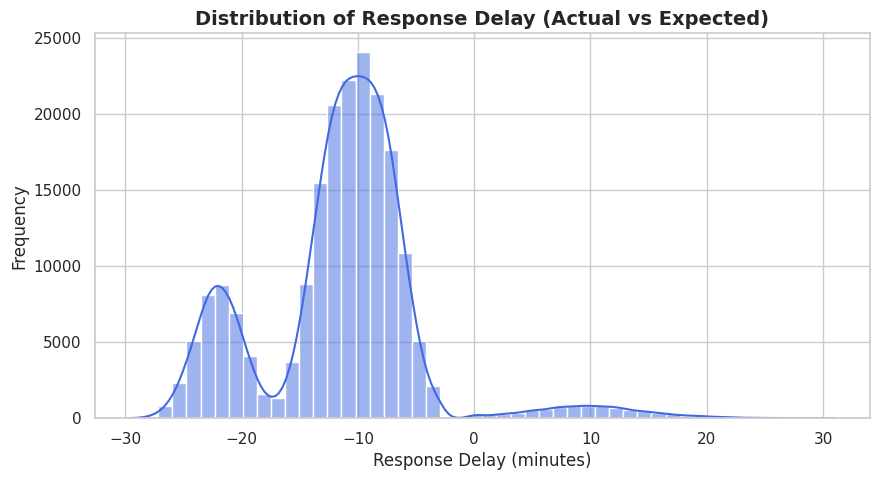

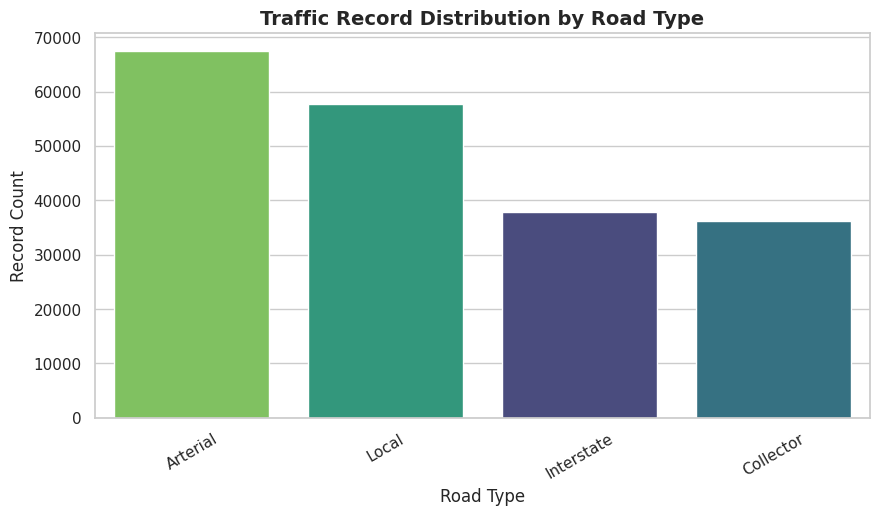

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style
sns.set_theme(style="whitegrid")

# 1. Distribution of Response Delay
plt.figure(figsize=(10, 5))
sns.histplot(
    df["Response_Delay_min"], bins=50, kde=True, color="royalblue"
)
plt.title(
    "Distribution of Response Delay (Actual vs Expected)",
    fontsize=14,
    fontweight="bold",
)
plt.xlabel("Response Delay (minutes)", fontsize=12)
plt.ylabel("Frequency", fontsize=12)
plt.show()

# 2. Record Frequency by Road Type
if "Road_Type" in df.columns:
  plt.figure(figsize=(10, 5))
  sns.countplot(
      data=df,
      x="Road_Type",
      order=df["Road_Type"].value_counts().index,
      palette="viridis",
      hue="Road_Type",
      legend=False,
  )
  plt.title(
      "Traffic Record Distribution by Road Type",
      fontsize=14,
      fontweight="bold",
  )
  plt.xlabel("Road Type", fontsize=12)
  plt.ylabel("Record Count", fontsize=12)
  plt.xticks(rotation=30)
  plt.show()

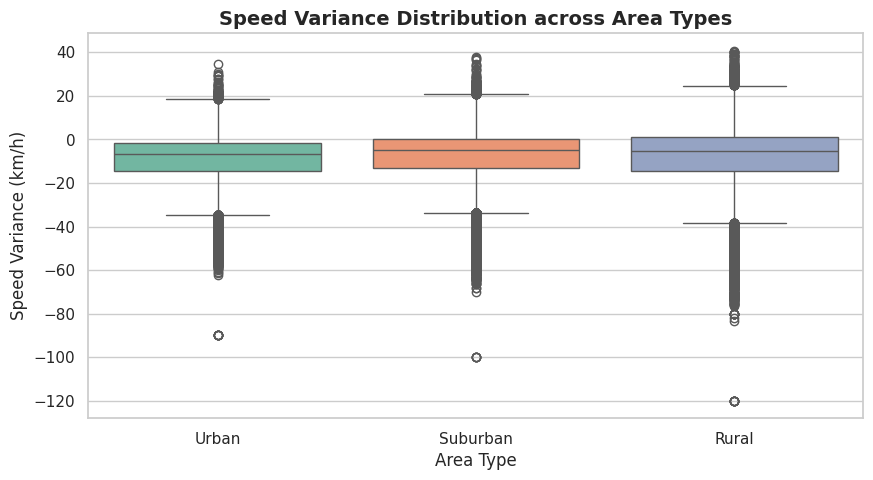

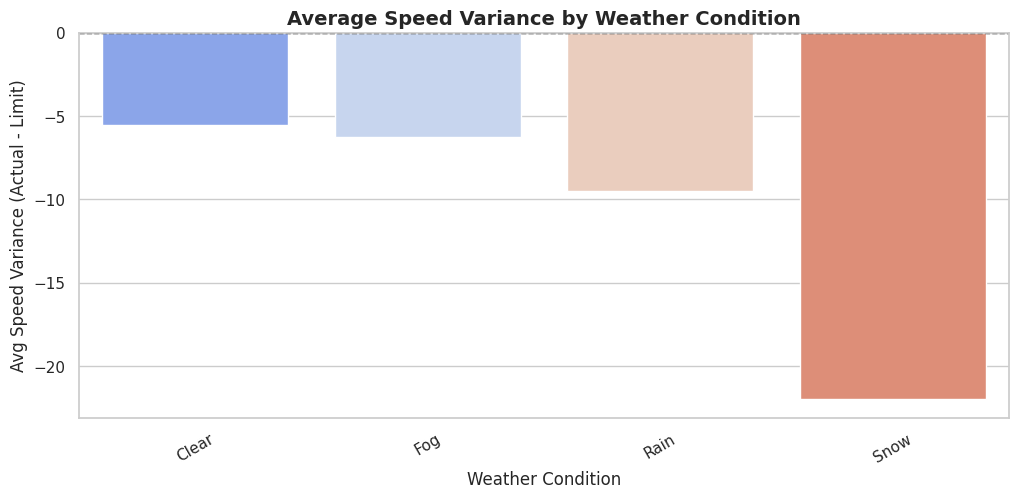

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Road & Area Context: Speed Variance by Area Type
if "Area_Type" in df.columns and "Speed_Variance_kmh" in df.columns:
  plt.figure(figsize=(10, 5))
  sns.boxplot(
      data=df,
      x="Area_Type",
      y="Speed_Variance_kmh",
      palette="Set2",
      hue="Area_Type",
      legend=False,
  )
  plt.title(
      "Speed Variance Distribution across Area Types",
      fontsize=14,
      fontweight="bold",
  )
  plt.xlabel("Area Type", fontsize=12)
  plt.ylabel("Speed Variance (km/h)", fontsize=12)
  plt.show()

# 4. Weather & Speed Compliance: Average Speed Variance by Weather Condition
if "Weather" in df.columns and "Speed_Variance_kmh" in df.columns:
  plt.figure(figsize=(12, 5))
  weather_speed = (
      df.groupby("Weather")["Speed_Variance_kmh"].mean().reset_index()
  )
  sns.barplot(
      data=weather_speed,
      x="Weather",
      y="Speed_Variance_kmh",
      palette="coolwarm",
      hue="Weather",
      legend=False,
  )
  plt.title(
      "Average Speed Variance by Weather Condition",
      fontsize=14,
      fontweight="bold",
  )
  plt.xlabel("Weather Condition", fontsize=12)
  plt.ylabel("Avg Speed Variance (Actual - Limit)", fontsize=12)
  plt.xticks(rotation=30)
  plt.axhline(0, color="black", linestyle="--", linewidth=1)  # Speed limit line
  plt.show()